In [ ]:
import category_encoders

In [3]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.options.display.float_format = '{:.5f}'.format

%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

In [4]:
train = pd.read_csv('../data/train.csv')
policies = pd.read_csv('../data/policies.csv')
test = pd.read_csv('../data/test.csv')
samplesubmission = pd.read_csv('../data/SampleSubmission.csv')

In [65]:
train.describe()

,sum_insured,target
count,9376.00000,9376.00000
mean,8534789.61723,41464.71125
std,112556487.28996,208434.71755
min,0.00000,0.00000
25%,6500.00000,287.92500
50%,50542.00000,1956.92500
75%,420000.00000,12700.64250
max,5211867675.00000,7868590.62000


In [66]:
train.nunique()

claim_id             9376
policy_number        4076
claim_number         9167
sum_insured          1299
product                37
agent                   8
class_of_business      37
risk_type              50
loss_date            1359
client_type             3
renewal_frequency       5
primary_cause          21
secondary_cause        74
branch                 11
target               6545
dtype: int64

In [36]:
policies.nunique()

policy_number         5217
product_code            37
trans_date           20836
from_date             1431
to_date               1369
agent                  223
class_of_business       37
client_type              3
renewal_frequency        5
branch                  11
dtype: int64

In [45]:
policies.shape

(30371, 10)

In [59]:
policies.head().sort_values('to_date',ascending=False)

,policy_number,product_code,trans_date,from_date,to_date,agent,class_of_business,client_type,renewal_frequency,branch
30367,pol000009519,prod00027,2021-11-01 14:33:18.620,2021-10-01 00:00:00.000,2022-09-30 00:00:00.000,ag00066,cob00031,ct0003,rf0002,br00001
30366,pol000005856,prod00015,2021-11-01 13:03:44.110,2021-11-01 00:00:00.000,2022-02-28 00:00:00.000,ag00006,cob00034,ct0001,rf0001,br00002
30370,pol000005913,prod00015,2021-11-01 16:02:25.817,2021-10-22 00:00:00.000,2022-01-31 00:00:00.000,ag00011,cob00034,ct0001,rf0001,br00002
30368,pol000007723,prod00015,2021-11-01 15:12:18.000,2021-11-01 00:00:00.000,2021-11-30 00:00:00.000,ag00021,cob00034,ct0001,rf0005,br00001
30369,pol000006085,prod00015,2021-11-01 15:54:55.943,2021-10-01 00:00:00.000,2021-10-31 00:00:00.000,ag00004,cob00034,ct0001,rf0005,br00002


In [53]:
policies = policies.sort_values('trans_date',ascending=False)
tmerge = train.merge(policies, how='left', left_on=['policy_number','product','agent',	'class_of_business',	'client_type',	'renewal_frequency'], right_on=['policy_number','product_code','agent',	'class_of_business',	'client_type',	'renewal_frequency'],suffixes=('','_policy'))

In [56]:
tmerge.shape

(17392, 20)

0

In [40]:
print(test.info())
print(train.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4019 entries, 0 to 4018
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   claim_id           4019 non-null   object 
 1   policy_number      3978 non-null   object 
 2   claim_number       4019 non-null   object 
 3   sum_insured        4019 non-null   float64
 4   product            4019 non-null   object 
 5   agent              4019 non-null   object 
 6   class_of_business  4019 non-null   object 
 7   risk_type          4019 non-null   object 
 8   loss_date          4019 non-null   object 
 9   client_type        4019 non-null   object 
 10  renewal_frequency  4019 non-null   object 
 11  primary_cause      4019 non-null   object 
 12  secondary_cause    4019 non-null   object 
 13  branch             4019 non-null   object 
dtypes: float64(1), object(13)
memory usage: 439.7+ KB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9376 entries, 0

In [ ]:
categoricals = ['product',
       'agent', 'class_of_business', 'risk_type', 'loss_date', 'client_type',
       'renewal_frequency', 'primary_cause', 'secondary_cause', 'branch',
       'target']

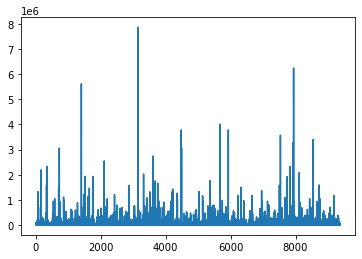

In [13]:
plt.plot((train.target))

<AxesSubplot:>

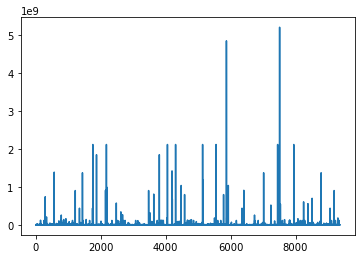

In [14]:
train.sum_insured.plot()

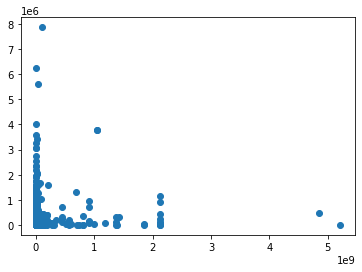

In [17]:
plt.scatter(x='sum_insured',y='target', data= train)

In [63]:
counts = policies.groupby('policy_number')['trans_date'].max()
counts.head()

policy_number
pol000005333    2019-08-23 15:26:34.417
pol000005334    2021-06-29 10:39:15.097
pol000005335    2020-11-26 10:23:25.967
pol000005336    2021-10-15 15:41:53.673
pol000005337    2019-02-28 18:00:30.500
Name: trans_date, dtype: object

In [61]:
cmerge = train.merge(counts, how='left',on='policy_number',suffixes='xx')
cmerge.head()

,claim_id,policy_number,claim_number,sum_insured,product,agent,class_of_business,risk_type,loss_date,client_type,renewal_frequency,primary_cause,secondary_cause,branch,target,product_code
0,ID_JZ7QWRHH57RO,pol000009680,claim0011359,300000.00000,prod00027,ag00068,cob00031,rt00006,2021-05-13,ct0003,rf0001,pc0007,sc00022,br00006,82150.00000,8.00000
1,ID_KQ5TJMVLJ4EP,pol000006869,claim0005272,16000.00000,prod00005,ag00226,cob00010,rt00032,2018-05-13,ct0003,rf0001,pc0007,sc00023,br00002,3780.24000,2.00000
2,ID_NYHI7WJGGIAE,pol000006135,claim0004147,3000.00000,prod00029,ag00037,cob00010,rt00026,2018-08-18,ct0003,rf0001,pc0007,sc00024,br00002,2196.50000,2.00000
3,ID_ROMMDCXYUXN5,pol000008991,claim0009962,6000.00000,prod00005,ag00037,cob00009,rt00032,2018-12-20,ct0003,rf0001,pc0007,sc00021,br00001,105.67000,6.00000
4,ID_2OTD9NX8L73D,pol000007768,claim0007346,26850.00000,prod00015,ag00226,cob00034,rt00023,2018-11-07,ct0001,rf0001,pc0007,sc00021,br00001,1605.64000,11.00000
